# 01 · Traffic exploration

Class balance, duplicates, missing values, campaign timing and potential leakage — before any model.
Data is a **synthetic** flow capture (no payloads, no real addresses).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from threatsense.common.config import get_settings
from threatsense.features.engineering import build_features, time_split
from threatsense.ingestion.loaders import load_flows, validate_flows

pd.set_option("display.width", 200)
s = get_settings()
raw = load_flows()
validate_flows(raw)

{'n_rows': 51120, 'missing_columns': [], 'null_cells': 0, 'duplicate_rows': 0, 'negative_values': 0, 'attack_rate': 0.182179186228482, 'categories': {'benign': 42000, 'dos': 3100, 'botnet': 3040, 'portscan': 1800, 'bruteforce': 1060, 'exfiltration': 120}, 'time_ordered': True}

## Class balance — accuracy would be misleading

In [2]:
raw.category.value_counts().to_frame("flows").assign(share=lambda d: (d.flows / d.flows.sum()).round(4))

,flows,share
category,,
benign,42000,0.8216
dos,3100,0.0606
botnet,3040,0.0595
portscan,1800,0.0352
bruteforce,1060,0.0207
exfiltration,120,0.0023


## When do campaigns happen? (drives the time-aware split)

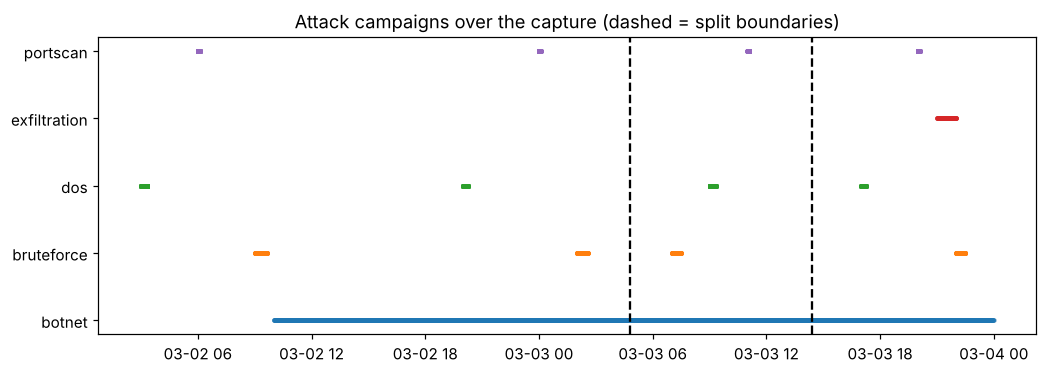

Text(0.5, 1.0, 'Attack campaigns over the capture (dashed = split boundaries)')

In [3]:
df = build_features(raw)
tr, va, te = time_split(df, 0.6, 0.2)
fig, ax = plt.subplots(figsize=(11, 3.5))
for cat, g in df[df.category != "benign"].groupby("category"):
    ax.scatter(g.timestamp, [cat] * len(g), s=4, alpha=.5)
for cut in (va.timestamp.min(), te.timestamp.min()):
    ax.axvline(cut, color="k", ls="--")
ax.set_title("Attack campaigns over the capture (dashed = split boundaries)")

## Feature separation (log scale)

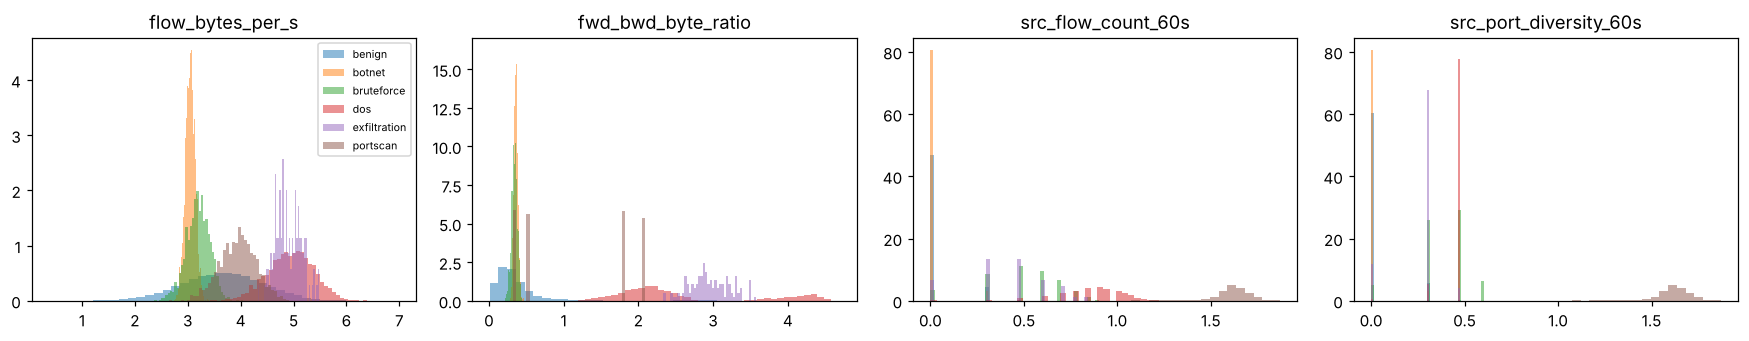

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, f in zip(axes, ["flow_bytes_per_s", "fwd_bwd_byte_ratio", "src_flow_count_60s", "src_port_diversity_60s"]):
    for cat, g in df.groupby("category"):
        ax.hist(np.log10(g[f] + 1), bins=40, alpha=.5, density=True, label=cat)
    ax.set_title(f)
axes[0].legend(fontsize=7)
plt.tight_layout()

**Leakage checks:** `flow_id`, `timestamp`, `src_ip` and `category` are excluded from model features;
context features look only backwards in time; `exfiltration` exists only in the test window.